## ENV ใช้ ELEVEN_LABS_API (เฉพาะขั้นตอนการทำเฉลย)

# Typhoon Whisper Large v3 — Thai ASR Pipeline

ทดลองใช้ `typhoon-ai/typhoon-whisper-large-v3` ถอดเสียงไฟล์ใน `data/` แล้ววัดผลด้วย **WER / CER / RTF**
โดยใช้ ElevenLabs Scribe ทำเฉลย (เก็บที่ `label/`)

1. Architecture  2. Data & EDA  3. ElevenLabs Labeling  4. Pre-processing  5. Modeling (3 แบบ)  6. Evaluation  7. Summary

In [1]:
import os, json, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
import noisereduce as nr
import requests, jiwer, torch
from scipy.signal import butter, sosfilt
from dotenv import load_dotenv
from IPython.display import Audio, display
from pythainlp.tokenize import word_tokenize
from transformers import WhisperConfig, WhisperForConditionalGeneration, pipeline

plt.rcParams["font.family"] = "Tahoma"  # รองรับภาษาไทยบน Windows

MODEL_ID = "typhoon-ai/typhoon-whisper-large-v3"
DATA_DIR, LABEL_DIR = Path("data"), Path("label")
SR = 16_000
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

C:\Users\BM MONEY\miniconda3\envs\hugging\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA GeForce RTX 2050


---
# 1. Architecture (ของเดิม)

**Typhoon Whisper Large v3** พัฒนาโดยทีม Typhoon (SCB 10X) โดย full fine-tune จาก `openai/whisper-large-v3`
ด้วยข้อมูลเสียงภาษาไทย ~11,000 ชม. (Gigaspeech2, CommonVoice, สื่อสาธารณะที่คัดแล้ว) — ไม่ได้เปลี่ยนโครงสร้างโมเดล
และฝึกให้เขียนตัวเลขเป็นคำอ่าน / ใช้ไม้ยมก (ๆ) ตามหลักภาษา (MIT · [arXiv:2601.13044](https://arxiv.org/abs/2601.13044))

<img src="https://raw.githubusercontent.com/openai/whisper/main/approach.png" width="700">

| ส่วน | หน้าที่ |
|---|---|
| Log-Mel Spectrogram | เสียง 16 kHz ช่วงละ 30 s → 128 mel × 3000 frames |
| Conv stem | Conv1D 2 ชั้น (stride 2) → 1500 frames × 1280 dim |
| Encoder | 32 blocks (Self-Attention + MLP) |
| Decoder | 32 blocks (Self-Attention + Cross-Attention + MLP) สร้าง token ทีละตัว |
| Output | vocab 51,866 tokens |

```
audio → 16 kHz mono → chunk 30 s → log-Mel → Encoder → Decoder(<|th|><|transcribe|>) → ข้อความ
```

นับพารามิเตอร์จาก config จริงบน `meta` device (ไม่ใช้ RAM/VRAM)

In [2]:
config = WhisperConfig.from_pretrained(MODEL_ID)
with torch.device("meta"):
    meta_model = WhisperForConditionalGeneration(config)

n = lambda m: sum(p.numel() for p in m.parameters())
enc, dec = meta_model.model.encoder, meta_model.model.decoder
print(f"d_model {config.d_model} | layers {config.encoder_layers}+{config.decoder_layers} | "
      f"heads {config.encoder_attention_heads} | mel {config.num_mel_bins} | vocab {config.vocab_size}")
params = pd.Series({"Encoder": n(enc), "Decoder": n(dec), "Total": n(meta_model)}, name="params")
del meta_model
params.map("{:,}".format).to_frame()

d_model 1280 | layers 32+32 | heads 20 | mel 128 | vocab 51866


,params
Encoder,"636,968,960"
Decoder,"906,521,600"
Total,"1,543,490,560"


---
# 2. Data & EDA

ข้อมูลเป็นไฟล์เพลง (mp3) ดิบ 2 ไฟล์ — **ไม่มีเฉลย** และมีดนตรีปนกับเสียงร้อง
- `GUNNER - แอ๊ดคาราบาว` : ภาษาไทย Base (มีปนอังกฤษ)
- `Taylor Swift - Opalite` : เพลงภาษาอังกฤษ (ทดสอบว่า Robust แค่ไหน)

In [3]:
files = sorted(DATA_DIR.glob("*.mp3"))
audio = {f.stem: librosa.load(f, sr=SR, mono=True)[0] for f in files}  # resample → 16 kHz mono

eda = pd.DataFrame([{
    "file": k,
    "size_MB": round(f.stat().st_size / 1e6, 2),
    "orig_sr": librosa.get_samplerate(f),
    "duration_s": round(len(y) / SR, 1),
    "rms_dBFS": round(20 * np.log10(np.sqrt(np.mean(y**2))), 1),
    "peak": round(np.abs(y).max(), 3),
    "silence_%": round(100 * (1 - sum(e - s for s, e in librosa.effects.split(y, top_db=40)) / len(y)), 1),
} for f, (k, y) in zip(files, audio.items())])
eda

,file,size_MB,orig_sr,duration_s,rms_dBFS,peak,silence_%
0,GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ),3.01,44100,187.0,-11.0,1.090,2.4
1,Taylor Swift - Opalite (Lyrics),3.78,44100,236.1,-11.8,1.232,1.8


In [4]:
# ฟังเสียงแต่ละไฟล์
for f in files:
    y = audio[f.stem]
    print(f"ไฟล์           : {f.name}")
    print(f"Sampling rate : {SR:,} Hz")
    print(f"จำนวน samples : {len(y):,}")
    print(f"ความยาว       : {len(y) / SR:.2f} วินาที")
    display(Audio(filename=str(f)))

ไฟล์           : GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ).mp3
Sampling rate : 16,000 Hz
จำนวน samples : 2,992,217
ความยาว       : 187.01 วินาที


ไฟล์           : Taylor Swift - Opalite (Lyrics).mp3
Sampling rate : 16,000 Hz
จำนวน samples : 3,777,608
ความยาว       : 236.10 วินาที


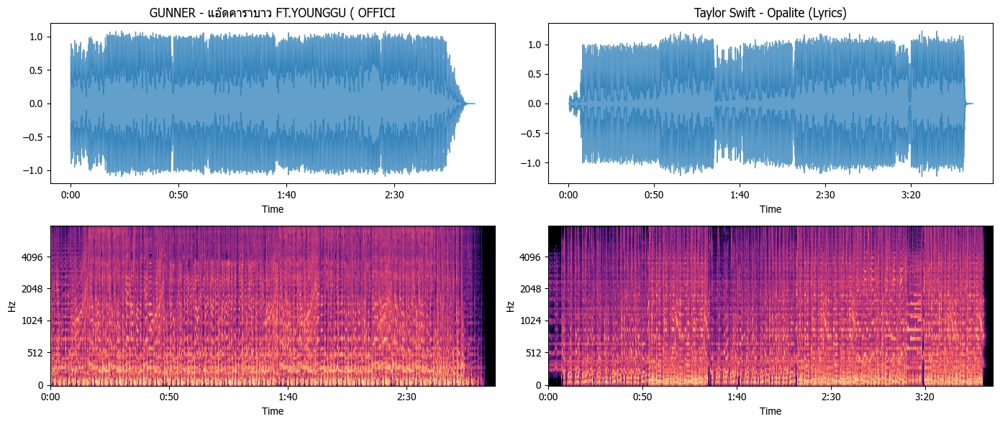

In [5]:
fig, axes = plt.subplots(2, len(audio), figsize=(14, 6))
for i, (k, y) in enumerate(audio.items()):
    librosa.display.waveshow(y, sr=SR, ax=axes[0, i], alpha=0.7)
    axes[0, i].set_title(k[:40])
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=128), ref=np.max)
    librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="mel", ax=axes[1, i])
plt.tight_layout(); plt.show()

**ข้อสังเกต:** ทั้งสองเพลงยาว ~3–4 นาที (เกิน 30 s ต้องตัด chunk), เสียงดังเกือบตลอด (silence ต่ำ)
และ mel spectrogram มีพลังงานดนตรีกระจายทุกย่านความถี่ → เสียงร้องถูกกลบบางส่วน

In [1]:
from pathlib import Path
from IPython.display import Audio, display

audio_files = sorted(Path("data").glob("*.mp3"))

print(f"Found {len(audio_files)} MP3 files")

for file in audio_files:
    print(f"\n🔊 {file.name}")
    display(Audio(filename=str(file)))

Found 2 MP3 files

🔊 GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ).mp3



🔊 Taylor Swift - Opalite (Lyrics).mp3


---
# 3. ElevenLabs Pre-Processing (ทำเฉลย)

ข้อมูลดิบไม่มี transcript จึงใช้ **ElevenLabs Scribe v2** (Speech-to-Text API) ถอดเสียงเป็นเฉลย และเก็บผลไว้ที่ `label/`
(ถ้ามีไฟล์แล้วจะไม่เรียก API ซ้ำ)


In [6]:
load_dotenv(".env")

def eleven_labs_stt(path):
    with open(path, "rb") as fh:
        r = requests.post("https://api.elevenlabs.io/v1/speech-to-text",
                          headers={"xi-api-key": os.environ["ELEVEN_LABS_API"]},
                          files={"file": (path.name, fh, "audio/mpeg")},
                          data={"model_id": "scribe_v2", "tag_audio_events": "false"}, timeout=600)
    r.raise_for_status()
    return r.json()

LABEL_DIR.mkdir(exist_ok=True)
labels = {}
for f in files:
    out = LABEL_DIR / f"{f.stem}.json"
    if not out.exists():
        out.write_text(json.dumps(eleven_labs_stt(f), ensure_ascii=False, indent=1), encoding="utf-8")
    labels[f.stem] = json.loads(out.read_text(encoding="utf-8"))

display(pd.DataFrame([{"file": k, "language": v["language_code"], "n_chars": len(v["text"])}
                      for k, v in labels.items()]))

for k, v in labels.items():
    print(f"\n===== {k} ({v['language_code']}) =====")
    print(v["text"])

,file,language,n_chars
0,GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ),tha,1462
1,Taylor Swift - Opalite (Lyrics),eng,1992



===== GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ) (tha) =====
You are listening to DJ Banglo. สจ. Gunner Network ครับ เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย พี่แอ๊ดพี่แน่มาก ช่วยคนที่ลำบากในเมืองไทย พี่แอ๊ดคาราบาว ขอบคุณที่ยืนหยัดอยู่กับคนไทย ขอบคุณ ขอบคุณ ขอบคุณ ขอบใจ ขอบใจ ขอบใจ ขอบคุณ ขอบคุณ ขอบคุณ ขอบใจ ขอบใจ ขอบใจ ขอบคุณที่ให้กำลังใจ น้องเนเน่เดินมาไกล บินไปอเมริกาแล้วรางวัลกลับมาให้คนไทย เพลงเนเน่แน่มากจะเป็นยังไง ผมกับ Gunner ก็ให้กำลังใจ ให้กำลังใจ พวกผมชอบเพลงนี้มากมาย มากมาย น้องเนเน่แน่มากจริง แน่มากจริง จัดไป ไม่ว่าหนทางจะไกล ไม่ว่าจะยากเพียงใด ไม่ว่าจะขึ้นลิฟต์หรือบันได เราจะยืนหยัดเข้มแข็งเหมือนหุ่นบันได ถ้าคุณรู้สึกว่าเรากดตี เราต้องขออภัย ขออภัย เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมือง

---
# 4. Pre-processing

- **เสียง:** โหลดเป็น 16 kHz mono แล้ว (ข้อ 2) ส่งเข้า pipeline เป็น array; ไฟล์ยาวตัดเป็น chunk 30 s (stride 5 s)
- **ข้อความ (สำหรับวัดผล):** ทำ normalization ทั้งเฉลยและผลโมเดลแบบเดียวกัน
  - ตัวพิมพ์เล็ก, ลบเครื่องหมายวรรคตอน
  - ภาษาไทยไม่มีเว้นวรรคระหว่างคำ → ตัดคำด้วย `pythainlp` (newmm) ก่อนคำนวณ WER
  - CER คำนวณบนตัวอักษรโดยไม่นับช่องว่าง

In [7]:
def normalize(text):
    text = re.sub(r"[^\w\s\u0E00-\u0E7F]", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

def to_words(text):
    return " ".join(w for w in word_tokenize(normalize(text), engine="newmm") if w.strip())

refs = {k: v["text"] for k, v in labels.items()}
for k, t in refs.items():
    print(k[:30], "→", to_words(t)[:100])

GUNNER - แอ๊ดคาราบาว FT.YOUNGG → you are listening to dj banglo สจ gunner network ครับ เขา คือ พี่ แอ๊ด คาราบาว เขา คือ พี่ แอ๊ด คารา
Taylor Swift - Opalite (Lyrics → i had a bad habit of missing lovers past my brother used to call it eating out of the trash it s nev


---
# 5. Modeling

โหลดโมเดลครั้งเดียวผ่าน HF `pipeline` (FP16 บน GPU) แล้วทดลอง 3 แบบ

In [8]:
asr = pipeline("automatic-speech-recognition", model=MODEL_ID, torch_dtype=DTYPE, device=DEVICE,
               chunk_length_s=30, batch_size=1)
asr.model.generation_config.forced_decoder_ids = None  # config เดิมชนกับ transformers รุ่นใหม่ → ใช้ language/task แทน

def transcribe(y, **gen_kwargs):
    t0 = time.time()
    text = asr({"raw": y, "sampling_rate": SR}, generate_kwargs=gen_kwargs)["text"].strip()
    return text, time.time() - t0

results = []  # เก็บผลทุกการทดลอง
def run(exp, inputs, **gen_kwargs):
    for k, y in inputs.items():
        text, sec = transcribe(y, **gen_kwargs)
        results.append({"experiment": exp, "file": k, "hyp": text, "time_s": sec, "duration_s": len(y) / SR})
        print(f"[{exp}] {k[:25]} ({sec:.1f}s): {text[:120]}")


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]


Loading checkpoint shards:  50%|█████     | 1/2 [00:11<00:11, 11.08s/it]


Loading checkpoint shards: 100%|██████████| 2/2 [00:13<00:00,  6.11s/it]


Loading checkpoint shards: 100%|██████████| 2/2 [00:13<00:00,  6.86s/it]

Device set to use cuda


## 5.1 Baseline
ใช้ค่าเริ่มต้นทั้งหมด (greedy decoding, ให้โมเดลตรวจภาษาเอง)

In [9]:
run("1_baseline", audio)

C:\Users\BM MONEY\miniconda3\envs\hugging\lib\site-packages\transformers\models\whisper\generation_whisper.py:573: FutureWarning: The input name `inputs` is deprecated. Please make sure to use `input_features` instead.
  warnings.warn(
Due to a bug fix in https://github.com/huggingface/transformers/pull/28687 transcription using a multilingual Whisper will default to language detection followed by transcription instead of translation to English.This might be a breaking change for your use case. If you want to instead always translate your audio to English, make sure to pass `language='en'`.


`generation_config` default values have been modified to match model-specific defaults: {'suppress_tokens': [], 'begin_suppress_tokens': [220, 50257]}. If this is not desired, please set these values explicitly.


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensLogitsProcessor'> to see related `.generate()` flags.


A custom logits processor of type <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.SuppressTokensAtBeginLogitsProcessor'> to see related `.generate()` flags.


[1_baseline] GUNNER - แอ๊ดคาราบาว FT.Y (93.5s): เขาคือมีแอดคาราบาวเขาคือมีแอดคาราบาวซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย เขาคือพี่แอ๊ด คาราบาว เขาคือพี่แอ๊


[1_baseline] Taylor Swift - Opalite (L (139.1s): I had a bad have been of nothing love has past My father used to call in eating out of the trash is never gonna last I t


## 5.2 Baseline + Audio Preprocessing / Enhancement
ปรับเสียงก่อนเข้าโมเดล เพื่อลดดนตรีที่กลบเสียงร้อง:
1. **Band-pass 100–4000 Hz** — ตัดเบส/กลองย่านต่ำ และย่านสูงที่ไม่ใช่เสียงร้องหลัก
2. **Noise reduction** (`noisereduce`, non-stationary) — ลดเสียงพื้นหลัง
3. **Peak normalization** — ปรับระดับเสียงให้สม่ำเสมอ

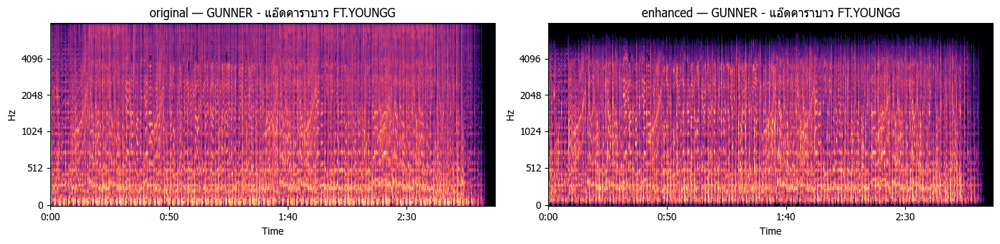

[2_enhanced] GUNNER - แอ๊ดคาราบาว FT.Y (84.0s): เขาคือพี่แอ๊ดคาราบาว คือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย เขาคือ


[2_enhanced] Taylor Swift - Opalite (L (131.5s): I had a bad have. A meeting love has. My brother used to call in.�ีดิงอ้าวเริ่มทราบ. It never gonna last. I. บอก my home


In [10]:
def enhance(y):
    y = sosfilt(butter(4, [100, 4000], btype="band", fs=SR, output="sos"), y)
    y = nr.reduce_noise(y=y, sr=SR, stationary=False, prop_decrease=0.8)
    return (0.95 * y / np.abs(y).max()).astype(np.float32)

audio_enh = {k: enhance(y) for k, y in audio.items()}

k0 = files[0].stem
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, (name, y) in zip(axes, [("original", audio[k0]), ("enhanced", audio_enh[k0])]):
    librosa.display.specshow(librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR), ref=np.max),
                             sr=SR, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(f"{name} — {k0[:30]}")
plt.tight_layout(); plt.show()

run("2_enhanced", audio_enh)

## 5.3 Baseline + Decoding Strategy Optimization
ปรับพารามิเตอร์ `generate()` แทนค่าเริ่มต้น บนเสียงต้นฉบับ:
- `num_beams` — beam search แทน greedy
- `language` — บังคับภาษาตามที่เฉลยระบุ แทนให้โมเดลเดาเอง
- `no_repeat_ngram_size` — กันโมเดลวนซ้ำ (hallucination loop) ที่เจอบ่อยในเพลง

ลองหลายชุดก่อน แล้วเลือกชุดที่ WER เฉลี่ยต่ำสุดเป็นตัวแทน

In [11]:
LANG = {k: {"tha": "th", "eng": "en"}.get(v["language_code"], "th") for k, v in labels.items()}

def wer(ref, hyp):
    return jiwer.wer(to_words(ref), to_words(hyp))

configs = {
    "greedy+lang":          {"language": "lang"},
    "beam5+lang":           {"num_beams": 5, "language": "lang"},
    "beam5+lang+no_repeat": {"num_beams": 5, "language": "lang", "no_repeat_ngram_size": 4},
}
grid = []
for name, cfg in configs.items():
    for k, y in audio.items():
        kw = {**cfg, "language": LANG[k]} if "language" in cfg else cfg
        text, sec = transcribe(y, **kw)
        grid.append({"config": name, "file": k, "hyp": text, "time_s": sec, "WER": wer(refs[k], text)})

grid = pd.DataFrame(grid)
display(grid.pivot(index="config", columns="file", values="WER").assign(mean=lambda d: d.mean(axis=1)).round(3))
best = grid.groupby("config")["WER"].mean().idxmin()
print("best config:", best, configs[best])

for r in grid[grid.config == best].itertuples():
    results.append({"experiment": "3_decoding", "file": r.file, "hyp": r.hyp,
                    "time_s": r.time_s, "duration_s": len(audio[r.file]) / SR})

You have passed language=th, but also have set `forced_decoder_ids` to [[1, None], [2, 50360]] which creates a conflict. `forced_decoder_ids` will be ignored in favor of language=th.


You have passed language=en, but also have set `forced_decoder_ids` to [[1, None], [2, 50360]] which creates a conflict. `forced_decoder_ids` will be ignored in favor of language=en.


file,GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV ),Taylor Swift - Opalite (Lyrics),mean
config,,,
beam5+lang,0.459,2.439,1.449
beam5+lang+no_repeat,0.645,0.909,0.777
greedy+lang,0.324,0.854,0.589


best config: greedy+lang {'language': 'lang'}


---
# 6. Evaluation

| Metric | ความหมาย |
|---|---|
| **WER** | Word Error Rate = (S + D + I) / N (ตัดคำไทยด้วย newmm) — ต่ำ = ดี |
| **CER** | Character Error Rate — เหมาะกับภาษาไทยมากกว่า เพราะไม่ขึ้นกับการตัดคำ |
| **S / D / I** | จำนวนคำที่ถูกแทน / ตกหล่น / เกินมา |
| **RTF** | Real-Time Factor = เวลาประมวลผล / ความยาวเสียง (< 1 = เร็วกว่า real-time) |

In [12]:
def score(row):
    ref, hyp = to_words(refs[row.file]), to_words(row.hyp)
    m = jiwer.process_words(ref, hyp)
    return pd.Series({
        "WER": m.wer,
        "CER": jiwer.cer(ref.replace(" ", ""), hyp.replace(" ", "")),
        "S": m.substitutions, "D": m.deletions, "I": m.insertions,
        "RTF": row.time_s / row.duration_s,
    })

res = pd.DataFrame(results)
res = pd.concat([res, res.apply(score, axis=1)], axis=1)
res["file"] = res.file.str[:25]

# ตารางรายไฟล์: ไล่สี WER/CER (เขียว = ดี) และตัวหนาค่าที่ดีที่สุดของแต่ละไฟล์
best_bold = lambda col: res.groupby("file")[col.name].transform("min").eq(col).map({True: "font-weight:bold", False: ""})
(res[["experiment", "file", "WER", "CER", "S", "D", "I", "RTF"]].style
    .background_gradient(subset=["WER", "CER"], cmap="RdYlGn_r", vmin=0, vmax=1)
    .apply(best_bold, subset=["WER", "CER"])
    .format({"WER": "{:.3f}", "CER": "{:.3f}", "RTF": "{:.2f}"})
    .hide(axis="index"))

experiment,file,WER,CER,S,D,I,RTF
1_baseline,GUNNER - แอ๊ดคาราบาว FT.Y,0.324,0.190,57.000000,23.000000,23.000000,0.50
1_baseline,Taylor Swift - Opalite (L,1.248,1.088,342.000000,9.000000,172.000000,0.59
2_enhanced,GUNNER - แอ๊ดคาราบาว FT.Y,0.374,0.253,61.000000,25.000000,33.000000,0.45
2_enhanced,Taylor Swift - Opalite (L,1.754,1.374,361.000000,10.000000,364.000000,0.56
3_decoding,GUNNER - แอ๊ดคาราบาว FT.Y,0.324,0.190,57.000000,23.000000,23.000000,0.47
3_decoding,Taylor Swift - Opalite (L,0.854,0.836,266.000000,90.000000,2.000000,0.45


,WER,CER,RTF
experiment,,,
1_baseline,0.786,0.639,0.545
2_enhanced,1.064,0.814,0.503
3_decoding,0.589,0.513,0.461


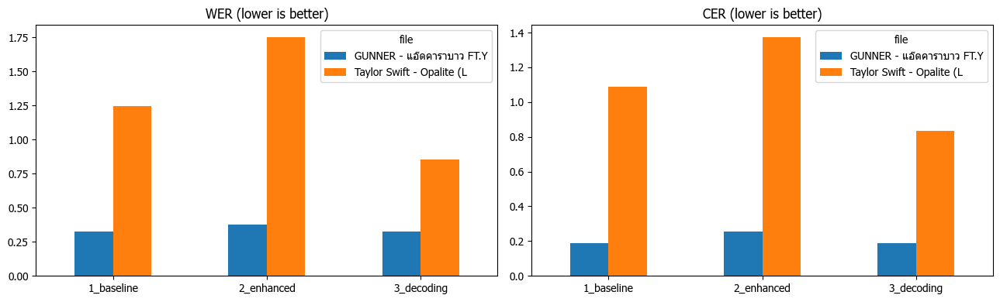

In [13]:
# ตารางสรุปเฉลี่ยต่อการทดลอง: highlight ค่าที่ดีที่สุดในแต่ละ metric
summary = res.groupby("experiment")[["WER", "CER", "RTF"]].mean()
display(summary.style
    .highlight_min(color="#b6e3b6")
    .highlight_max(subset=["WER", "CER"], color="#f4b6b6")
    .format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["WER", "CER"]):
    res.pivot(index="experiment", columns="file", values=metric).plot.bar(ax=ax, rot=0)
    ax.set_title(f"{metric} (lower is better)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

ตัวอย่างข้อความเทียบเฉลย (200 ตัวอักษรแรก)

In [14]:
for k in refs:
    print(f"=== {k}\n[REF]           {refs[k][:200]}")
    for r in res[res.file == k[:25]].itertuples():
        print(f"[{r.experiment:<14}] {r.hyp[:200]}")
    print()

=== GUNNER - แอ๊ดคาราบาว FT.YOUNGGU ( OFFICIAL MV )
[REF]           You are listening to DJ Banglo. สจ. Gunner Network ครับ เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย เขาคือพี่แอ๊ดคาราบาว เขาคือพี่แอ๊ดคาราบาว ซุปเปอร์ฮี
[1_baseline    ] เขาคือมีแอดคาราบาวเขาคือมีแอดคาราบาวซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย เขาคือพี่แอ๊ด คาราบาว เขาคือพี่แอ๊ด คาราบาว ซุปเปอร์อีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย พี่แอ๊ด พี่แน่มาก ช่
[2_enhanced    ] เขาคือพี่แอ๊ดคาราบาว คือพี่แอ๊ดคาราบาว ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย เขาคือพี่แอ๊ด คาราบาว เขาคือพี่แอ๊ด คาราบาว ซุปเปอร์อีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเ
[3_decoding    ] เขาคือมีแอดคาราบาวเขาคือมีแอดคาราบาวซุปเปอร์ฮีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย เขาคือพี่แอ๊ด คาราบาว เขาคือพี่แอ๊ด คาราบาว ซุปเปอร์อีโร่ของเมืองไทย ซุปเปอร์อีโร่ของเมืองไทย พี่แอ๊ด พี่แน่มาก ช่

=== Taylor Swift - Opalite (Lyrics)
[REF]           I had a bad habit of mis

---
# 7. Summary

| Experiment | GUNNER (ไทย) WER / CER | Opalite (อังกฤษ) WER / CER | Mean WER | Mean RTF |
|---|---|---|---|---|
| 1. Baseline | 0.324 / 0.190 | 1.248 / 1.088 | 0.786 | 0.55 |
| 2. + Audio Enhancement | 0.374 / 0.253 | 1.754 / 1.374 | 1.064 | 0.50 |
| 3. + Decoding (greedy + บังคับภาษา) | **0.324 / 0.190** | **0.854 / 0.836** | **0.589** | **0.46** |

**สรุปผล**
- **เพลงไทย:** Baseline ทำได้ดีพอสมควร (CER ~19%) ถอดท่อนหลักได้ถูก ผิดเฉพาะคำที่ร้องเร็ว/ถูกดนตรีกลบ เช่น "พี่แอ๊ด" → "มีแอด", "ฮีโร่" → "อีโร่"
- **เพลงอังกฤษ:** Baseline พังหนัก (WER > 1) เพราะโมเดลถูก fine-tune มาเป็นภาษาไทย และเกิด **hallucination / วนซ้ำ** (Insertions 172 คำ)
- **Audio Enhancement แย่ลงทั้งสองไฟล์:** band-pass + noise reduction ตัดรายละเอียดเสียงร้องไปด้วย ทำให้โมเดลสลับภาษาไปมาและวนซ้ำหนักขึ้น → การกรองเสียงแบบง่ายไม่เหมาะกับเพลง (ควรใช้ vocal separation เช่น Demucs)
- **Decoding Optimization ดีที่สุด:** ตัวที่ได้ผลจริงคือ **บังคับ `language`** ช่วยลด insertions ของเพลงอังกฤษจาก 172 → 2 คำ (WER 1.25 → 0.85) ส่วน **beam search กลับแย่ลง** (วนซ้ำมากขึ้นในเพลงอังกฤษ) และช้ามากบน GPU 4 GB; `no_repeat_ngram_size` ลดการวนซ้ำได้แต่ไปตัดท่อนฮุคที่ร้องซ้ำจริงจนผิดเพิ่ม
- **ความเร็ว:** RTF ~0.5 บน RTX 2050 (FP16) → เร็วกว่า real-time ราว 2 เท่า

**ข้อจำกัด:** ข้อมูลเพียง 2 เพลง และเฉลยมาจาก ElevenLabs (silver label) ผลจึงเป็นแนวโน้มเบื้องต้น ไม่ใช่ benchmark ที่สรุปได้แน่นอน
